In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

def find_repo_root(start: Path) -> Path:
    for parent in [start] + list(start.parents):
        if (parent / "studies").is_dir() and (parent / "run_uc2_age_based.py").exists():
            return parent
    return start

REPO_ROOT = find_repo_root(Path.cwd())
print(f"Repo root: {REPO_ROOT}")

def load_standard_eval(folder: Path):
    eval_path = folder / "standard_eval.csv"
    if not eval_path.exists():
        return None
    df = pd.read_csv(eval_path, index_col=0)
    col = "MoD_0" if "MoD_0" in df.columns else df.columns[0]
    def metric(key):
        return df.loc[key, col] if key in df.index else None
    return {
        "scenario": folder.name,
        "service_rate_pct": metric("served online users [%]"),
        "avg_wait_s": metric("waiting time"),
        "median_wait_s": metric("waiting time (median)"),
        "p90_wait_s": metric("waiting time (90% quantile)"),
        "utilization_pct": metric("% fleet utilization"),
        "num_users": metric("number users"),
        "num_travelers": metric("number travelers"),
        "total_vkm": metric("total vkm"),
    }

def load_case_results(results_dir: Path) -> pd.DataFrame:
    if not results_dir.exists():
        return pd.DataFrame()
    rows = []
    for folder in sorted([p for p in results_dir.iterdir() if p.is_dir()]):
        row = load_standard_eval(folder)
        if row:
            rows.append(row)
    return pd.DataFrame(rows)

def add_track_cols(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["track"] = np.where(out["scenario"].str.endswith("__trips"), "trips", "baseline")
    out["scenario_base"] = out["scenario"].str.replace("__trips", "", regex=False)
    return out

Repo root: /Users/danieldeutsch/Desktop/code_projects/FleetPy


# Cross-Hypothesis Results Investigation

This notebook loads results directly from the study result folders and summarizes service rate, wait times, and utilization for H1 (Use Case 1), UC2, and UC3.

Run the simulations before executing these cells. Results are expected under:
- studies/klagenfurt_h1_spitzenzeiten_case_study/results
- studies/uc2_age_based/results
- studies/uc3_accessibility/results

## Definitionen (Use Cases und Hypothesen)

- H1 (Spitzenzeiten Klagenfurt): Nachfrage auf dem Klagenfurt-Netz, Flottenvarianten mit 20/30/40 Fahrzeugen. Zeitfenster 06:00-22:00, Standard-Pooling (Alonso-Mora), max. Wartezeit 480s, Detour-Faktor 40.
- H2 (kurzes Spitzenzeitfenster): Gleiche Logik wie H1, aber Zeitfenster 07:00-09:00 und kleinere Flotten (8/16/24/32 Fahrzeuge).
- UC2 (Altersbasierte digitale Kompetenz): Nutzerparameter wie Entscheidungszeit, Wartezeit-Toleranz, Gehgeschwindigkeit und Boarding-Zeit variieren je Szenario.
- UC3 (Barrierefreiheit): Flottenmischung aus Standard- und barrierefreien Fahrzeugen; Wartezeitvorgaben sind gleich.

## Wie die Kennzahlen zu lesen sind

- service_rate_pct = Anteil der bedienten Online-Requests in Prozent. 4% bedeutet: 4 von 100 Anfragen wurden bedient.
- avg_wait_min = mittlere Wartezeit in Minuten fuer die bedienten Nutzer.
- utilization_pct = Flottenauslastung in Prozent.
- num_users = Anzahl der Nutzer in der Auswertung (absolut, nicht Prozent).

In [2]:
import yaml

rule_files = {
    "H1": REPO_ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "scenarios" / "const_cfg_klagenfurt_h1_spitzenzeiten_case_study.yaml",
    "H2": REPO_ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "scenarios" / "const_cfg_klagenfurt_h2_spitzenzeiten_case_study.yaml",
    "UC2": REPO_ROOT / "studies" / "uc2_age_based" / "scenarios" / "const_cfg_uc2.yaml",
    "UC3": REPO_ROOT / "studies" / "uc3_accessibility" / "scenarios" / "const_cfg_uc3.yaml",
}

rule_rows = []
for label, path in rule_files.items():
    if not path.exists():
        continue
    with path.open("r", encoding="utf-8") as fh:
        cfg = yaml.safe_load(fh)
    start_time = cfg.get("start_time")
    end_time = cfg.get("end_time")
    max_wait = cfg.get("op_max_wait_time")
    detour = cfg.get("op_max_detour_time_factor")
    rule_rows.append(
        {
            "study": label,
            "start_time_s": start_time,
            "end_time_s": end_time,
            "time_window_h": (end_time - start_time) / 3600 if start_time is not None and end_time is not None else None,
            "max_wait_s": max_wait,
            "max_wait_min": max_wait / 60 if max_wait is not None else None,
            "max_detour_factor": detour,
        }
    )

rules_df = pd.DataFrame(rule_rows)
if not rules_df.empty:
    display(rules_df.sort_values("study").reset_index(drop=True))
else:
    print("Keine Regel-Configs gefunden.")

,study,start_time_s,end_time_s,time_window_h,max_wait_s,max_wait_min,max_detour_factor
0,H1,21600,79200,16.0,480,8.0,40
1,H2,25200,32400,2.0,480,8.0,40
2,UC2,25200,32400,2.0,480,8.0,40
3,UC3,25200,32400,2.0,480,8.0,40


In [3]:
zone_map_path = REPO_ROOT / "data" / "zones" / "klagenfurt_h1_spitzenzeiten" / "adapted_to_moia_data" / "node_zone_info.csv"
demand_dir = REPO_ROOT / "data" / "demand" / "klagenfurt_h1_spitzenzeiten" / "matched" / "klagenfurt_h1_spitzenzeiten"

request_files = {
    "baseline": demand_dir / "demand_requests.csv",
    "trips": demand_dir / "demand_requests_trips.csv",
}

if not zone_map_path.exists():
    print("Zone mapping nicht gefunden:", zone_map_path)
else:
    zones = pd.read_csv(zone_map_path)
    node_to_zone = zones.set_index("node_index")["zone_id"].to_dict()

    rows = []
    for track, path in request_files.items():
        if not path.exists():
            print("Request-Datei fehlt:", path)
            continue
        req = pd.read_csv(path)
        if "start" not in req.columns:
            print("Spalte 'start' fehlt in:", path)
            continue
        start_nodes = req["start"].astype(int)
        start_zones = start_nodes.map(node_to_zone)
        counts = start_zones.value_counts(dropna=False).sort_index()
        total = float(counts.sum()) if len(counts) else 0.0
        for zone_id, count in counts.items():
            rows.append(
                {
                    "track": track,
                    "zone_id": zone_id,
                    "requests": float(count),
                    "share_pct": (count / total * 100.0) if total else 0.0,
                    "total_requests": total,
                }
            )

    if rows:
        zone_df = pd.DataFrame(rows)
        num_cols = zone_df.select_dtypes(include="number").columns
        zone_df[num_cols] = zone_df[num_cols].round(2)
        display(zone_df.sort_values(["track", "zone_id"]))
    else:
        print("Keine Zonen-Cluster Daten gefunden.")

,track,zone_id,requests,share_pct,total_requests
0,baseline,1.0,84.0,16.80,500.0
1,baseline,2.0,52.0,10.40,500.0
2,baseline,3.0,35.0,7.00,500.0
3,baseline,4.0,130.0,26.00,500.0
4,baseline,5.0,4.0,0.80,500.0
5,baseline,NaN,195.0,39.00,500.0
6,trips,1.0,81.0,10.45,775.0
7,trips,2.0,186.0,24.00,775.0
8,trips,3.0,120.0,15.48,775.0
9,trips,4.0,150.0,19.35,775.0


### Zonen-Cluster: Requests je Startzone (baseline vs trips)

Diese Tabelle zeigt, wie viele Requests in welcher Zone starten. Quelle: demand_requests.csv und demand_requests_trips.csv, gemappt mit node_zone_info.csv aus adapted_to_moia_data.

### Regeln in Klartext

- max_wait_s = maximale Wartezeit pro Request in Sekunden. Beispiel: 480 bedeutet 8 Minuten.
- max_detour_factor = maximal erlaubter Umwegfaktor (z.B. 40 bedeutet sehr hohe Toleranz).
- time_window_h = Dauer des Simulationszeitfensters in Stunden (end_time - start_time).

## Grundsaetzliche absolute Werte

Die Tabellen unten zeigen relative Kennzahlen. Hier sind zusaetzliche absolute Infos:
- Flottengroesse je Szenario (Anzahl Fahrzeuge)
- Anzahl Nutzer und Reisende (absolute Werte) in den Resultat-Tabellen

Hinweis: Sitzplaetze je Fahrzeugtyp stehen in den Fahrzeug-Definitionen, sind hier aber nicht automatisch geladen.

## Absolute Bedienungs-Schaetzung (aus den Auswertungen)

Hinweis: In standard_eval.csv steht nur eine begrenzte Menge an absoluten Kennzahlen. Die Tabelle unten nutzt:
- num_users als Gesamtzahl der Online-Requests (laut Auswertung)
- service_rate_pct zur Schaetzung der bedienten Requests

Damit gilt die Schaetzung: served_users_est = num_users * service_rate_pct / 100.

In [4]:
study_dirs = {
    "H1": REPO_ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "results",
    "H2": REPO_ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "results",
    "UC2": REPO_ROOT / "studies" / "uc2_age_based" / "results",
    "UC3": REPO_ROOT / "studies" / "uc3_accessibility" / "results",
}

abs_rows = []
for label, results_dir in study_dirs.items():
    df = load_case_results(results_dir)
    if df.empty:
        continue
    df = add_track_cols(df)
    df["served_users_est"] = df["num_users"] * df["service_rate_pct"] / 100.0
    df["unserved_users_est"] = df["num_users"] - df["served_users_est"]
    df["study"] = label
    abs_rows.append(
        df[[
            "study",
            "scenario",
            "track",
            "num_users",
            "service_rate_pct",
            "served_users_est",
            "unserved_users_est",
            "num_travelers",
        ]]
    )

if abs_rows:
    abs_df = pd.concat(abs_rows, ignore_index=True)
    abs_df = abs_df.sort_values(["study", "scenario", "track"]).reset_index(drop=True)
    abs_df_round = abs_df.copy()
    num_cols = abs_df_round.select_dtypes(include="number").columns
    abs_df_round[num_cols] = abs_df_round[num_cols].round(2)
    display(abs_df_round)
else:
    print("Keine absoluten Kennzahlen gefunden.")

,study,scenario,track,num_users,service_rate_pct,served_users_est,unserved_users_est,num_travelers
0,H1,klagenfurt_h1_spitzenzeiten_scenario_1,baseline,9.0,1.80,0.16,8.84,9.0
1,H1,klagenfurt_h1_spitzenzeiten_scenario_1__trips,trips,9.0,1.16,0.10,8.90,9.0
2,H1,klagenfurt_h1_spitzenzeiten_scenario_1__trips_...,baseline,9.0,1.16,0.10,8.90,9.0
3,H1,klagenfurt_h1_spitzenzeiten_scenario_1__trips_...,baseline,5.0,0.65,0.03,4.97,5.0
4,H1,klagenfurt_h1_spitzenzeiten_scenario_2,baseline,9.0,1.80,0.16,8.84,9.0
...,...,...,...,...,...,...,...,...
66,UC3,mixed_30__trips__svc_wait_300,baseline,3.0,4.69,0.14,2.86,3.0
67,UC3,mixed_50,baseline,5.0,1.43,0.07,4.93,5.0
68,UC3,mixed_50__trips,trips,3.0,4.69,0.14,2.86,3.0
69,UC3,mixed_50__trips__repo_basic,baseline,3.0,4.69,0.14,2.86,3.0


### Hinweis zur Interpretation von served_users_est

- served_users_est ist eine rechnerische Schaetzung, keine ganze Zahl.
- Beispiel: num_users = 9 und service_rate_pct = 1.1% ergibt 0.10. Das heisst: Im Mittel wird praktisch niemand bedient.
- Eine sehr kleine Zahl zeigt, dass fast alle Requests an den Regeln scheitern (Wartezeit, Detour, Zeitfenster, Entfernung) oder dass sie zeitlich/geografisch stark gebuendelt sind.

In [5]:
def parse_fleet_size(comp: str) -> int:
    if not isinstance(comp, str) or not comp:
        return 0
    total = 0
    for part in comp.split(";"):
        if ":" in part:
            _, count = part.split(":", 1)
            try:
                total += int(count)
            except ValueError:
                pass
    return total

fleet_rows = []

# H1 and H2 fleet sizes from scenario CSVs
h1_sc = REPO_ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "scenarios" / "scenario_cfg_klagenfurt_h1_spitzenzeiten_case_study.csv"
h2_sc = REPO_ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "scenarios" / "scenario_cfg_klagenfurt_h2_spitzenzeiten_case_study.csv"

if h1_sc.exists():
    df = pd.read_csv(h1_sc)
    df["fleet_size"] = df["op_fleet_composition"].astype(str).map(parse_fleet_size)
    for _, row in df.iterrows():
        fleet_rows.append({"study": "H1", "scenario": row["scenario_name"], "fleet_size": row["fleet_size"]})

if h2_sc.exists():
    df = pd.read_csv(h2_sc)
    df["fleet_size"] = df["op_fleet_composition"].astype(str).map(parse_fleet_size)
    for _, row in df.iterrows():
        fleet_rows.append({"study": "H2", "scenario": row["scenario_name"], "fleet_size": row["fleet_size"]})

# UC2 fleet size from const config (default_vehtype: 20)
uc2_fleet_size = 20
uc2_sc = REPO_ROOT / "studies" / "uc2_age_based" / "scenarios" / "uc2_scenarios.csv"
if uc2_sc.exists():
    df = pd.read_csv(uc2_sc)
    for _, row in df.iterrows():
        fleet_rows.append({"study": "UC2", "scenario": row["scenario_name"], "fleet_size": uc2_fleet_size})

# UC3 fleet sizes from scenario CSV
uc3_sc = REPO_ROOT / "studies" / "uc3_accessibility" / "scenarios" / "uc3_scenarios.csv"
if uc3_sc.exists():
    df = pd.read_csv(uc3_sc)
    df["fleet_size"] = df["op_fleet_composition"].astype(str).map(parse_fleet_size)
    for _, row in df.iterrows():
        fleet_rows.append({"study": "UC3", "scenario": row["scenario_name"], "fleet_size": row["fleet_size"]})

fleet_info = pd.DataFrame(fleet_rows)
if not fleet_info.empty:
    display(fleet_info.sort_values(["study", "scenario"]))
else:
    print("Keine Flotteninformationen gefunden.")

print("Hinweis: Sitzplaetze sind in den Fahrzeugdefinitionen hinterlegt und werden hier nicht automatisch geladen.")

,study,scenario,fleet_size
0,H1,klagenfurt_h1_spitzenzeiten_scenario_1,20
1,H1,klagenfurt_h1_spitzenzeiten_scenario_2,30
2,H1,klagenfurt_h1_spitzenzeiten_scenario_3,40
3,H2,klagenfurt_h2_spitzenzeiten_scenario_1,8
4,H2,klagenfurt_h2_spitzenzeiten_scenario_2,16
5,H2,klagenfurt_h2_spitzenzeiten_scenario_3,24
6,H2,klagenfurt_h2_spitzenzeiten_scenario_4,32
7,UC2,baseline,20
10,UC2,full_support,20
8,UC2,phone_support,20


Hinweis: Sitzplaetze sind in den Fahrzeugdefinitionen hinterlegt und werden hier nicht automatisch geladen.


,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users,num_travelers,total_vkm
0,klagenfurt_h1_spitzenzeiten_scenario_1,baseline,1.800000,4.555556,6.0,7.100000,1.196620,9.0,9.0,52.706331
1,klagenfurt_h1_spitzenzeiten_scenario_1,trips,1.161290,7.222222,5.5,13.500000,1.115122,9.0,9.0,45.306243
2,klagenfurt_h1_spitzenzeiten_scenario_1__repo_b...,baseline,1.161290,7.222222,5.5,13.500000,1.115122,9.0,9.0,45.306243
3,klagenfurt_h1_spitzenzeiten_scenario_1__svc_wa...,baseline,0.645161,3.500000,3.5,4.600000,0.404511,5.0,5.0,15.828620
4,klagenfurt_h1_spitzenzeiten_scenario_2,baseline,1.800000,4.555556,6.0,7.100000,0.797747,9.0,9.0,52.706331
5,klagenfurt_h1_spitzenzeiten_scenario_2,trips,1.161290,7.222222,5.5,13.500000,0.743415,9.0,9.0,45.306243
6,klagenfurt_h1_spitzenzeiten_scenario_2__repo_b...,baseline,1.161290,7.222222,5.5,13.500000,0.743415,9.0,9.0,45.306243
7,klagenfurt_h1_spitzenzeiten_scenario_2__svc_wa...,baseline,0.645161,3.500000,3.5,4.600000,0.269674,5.0,5.0,15.828620
8,klagenfurt_h1_spitzenzeiten_scenario_3,baseline,3.000000,4.139686,3.5,6.500000,0.992972,15.0,15.0,87.325283
9,klagenfurt_h1_spitzenzeiten_scenario_3,trips,2.064516,6.762693,3.5,10.500000,0.902118,16.0,16.0,78.802825


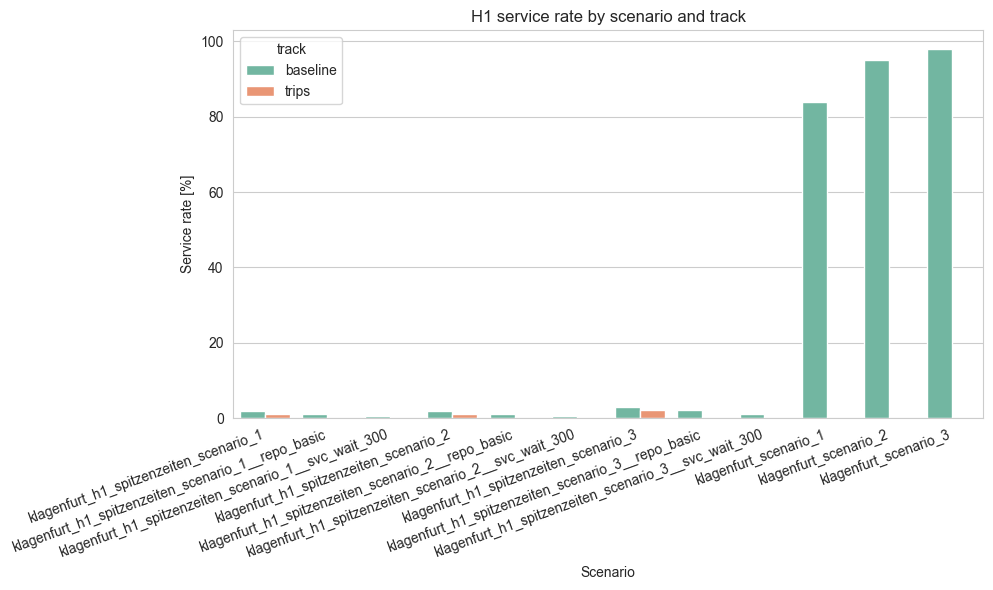

In [6]:
# H1 (Use Case 1) results
h1_results_dir = REPO_ROOT / "studies" / "klagenfurt_h1_spitzenzeiten_case_study" / "results"
h1_df = load_case_results(h1_results_dir)

if h1_df.empty:
    print("No H1 results found in:", h1_results_dir)
else:
    h1_df = add_track_cols(h1_df)
    h1_df["avg_wait_min"] = h1_df["avg_wait_s"] / 60
    h1_df["median_wait_min"] = h1_df["median_wait_s"] / 60
    h1_df["p90_wait_min"] = h1_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
        "num_travelers",
        "total_vkm",
    ]
    display(h1_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=h1_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("H1 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

### Interpretation H1 (Spitzenzeiten)

Konfiguration:
- Zeitfenster 06:00-22:00 (start_time 21600, end_time 79200)
- Flottenvarianten: 20 / 30 / 40 Fahrzeuge
- max. Wartezeit 480s, Detour-Faktor 40, Repositioning: None

Warum sind die Werte bei klagenfurt_scenario_1/2/3 relativ hoch?
- Das sind die H1-Baseline-Szenarien mit synthetischer Nachfrage und groesserer Flotte. Diese Kombination fuehrt zu hoeherer Service-Rate.
- In den __trips-Varianten ist die Nachfrage anders skaliert und zeitlich/geografisch verteilt; dadurch faellt die Service-Rate oft deutlich niedriger aus.
- service_rate_pct ist ein Prozentwert der Online-Requests. Bei kleinen absoluten Zahlen kann der Prozentwert stark schwanken.

## H2 results (baseline vs trips)

Scenarios include fleet sizes 8, 16, 24, 32. Trips results are suffixed with `__trips`.

,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users,num_travelers,total_vkm
0,klagenfurt_h2_spitzenzeiten_scenario_1,baseline,0.857143,7.333333,8.0,8.0,8.337459,3.0,3.0,18.553601
1,klagenfurt_h2_spitzenzeiten_scenario_1,trips,4.687500,6.166667,3.5,10.3,5.373237,3.0,3.0,10.136825
2,klagenfurt_h2_spitzenzeiten_scenario_1__repo_b...,baseline,4.687500,6.166667,3.5,10.3,5.373237,3.0,3.0,10.136825
3,klagenfurt_h2_spitzenzeiten_scenario_1__svc_wa...,baseline,1.562500,3.000000,3.0,3.0,1.354167,1.0,1.0,3.351196
4,klagenfurt_h2_spitzenzeiten_scenario_2,baseline,1.142857,6.875000,7.0,8.0,5.080188,4.0,4.0,21.133193
5,klagenfurt_h2_spitzenzeiten_scenario_2,trips,4.687500,3.500000,3.5,3.9,2.269952,3.0,3.0,8.805810
6,klagenfurt_h2_spitzenzeiten_scenario_2__repo_b...,baseline,4.687500,3.500000,3.5,3.9,2.269952,3.0,3.0,8.805810
7,klagenfurt_h2_spitzenzeiten_scenario_2__svc_wa...,baseline,4.687500,3.500000,3.5,3.9,2.269952,3.0,3.0,8.805810
8,klagenfurt_h2_spitzenzeiten_scenario_3,baseline,2.571429,4.977036,6.0,8.0,6.816495,9.0,9.0,42.912323
9,klagenfurt_h2_spitzenzeiten_scenario_3,trips,4.687500,3.000000,3.0,3.8,1.461218,3.0,3.0,8.350778


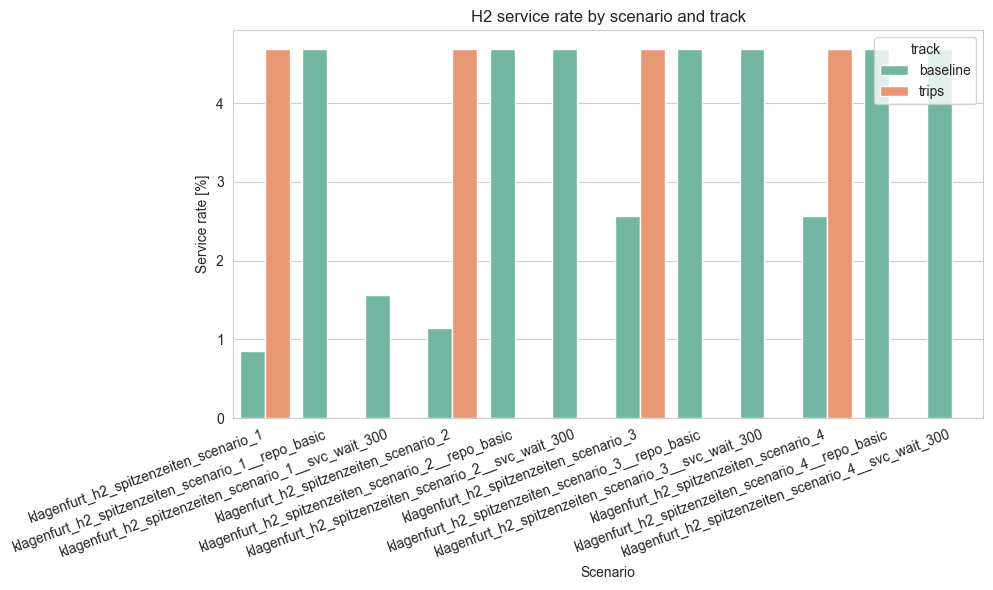

In [7]:
h2_results_dir = REPO_ROOT / "studies" / "klagenfurt_h2_spitzenzeiten_case_study" / "results"
h2_df = load_case_results(h2_results_dir)

if h2_df.empty:
    print("No H2 results found in:", h2_results_dir)
else:
    h2_df = add_track_cols(h2_df)
    h2_df["avg_wait_min"] = h2_df["avg_wait_s"] / 60
    h2_df["median_wait_min"] = h2_df["median_wait_s"] / 60
    h2_df["p90_wait_min"] = h2_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
        "num_travelers",
        "total_vkm",
    ]
    display(h2_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=h2_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("H2 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

### Interpretation H2 (kurzes Spitzenzeitfenster)

Konfiguration:
- Zeitfenster 07:00-09:00 (start_time 25200, end_time 32400)
- Flottenvarianten: 8 / 16 / 24 / 32 Fahrzeuge
- max. Wartezeit 480s, Detour-Faktor 40, Repositioning: None

Warum ist die Service-Rate oft nur ~4%?
- 4% bedeutet: Nur 4 von 100 Online-Requests wurden bedient.
- Mit kurzer Spitzenzeit und kleiner Flotte reicht die Kapazitaet oft nicht aus.
- Dieses Notebook zeigt nur aggregierte Kennzahlen, nicht die exakten Fahrzeugbewegungen. Um "welches Auto wohin" zu sehen, braucht man die Replay/Route-Outputs je Szenario.
- Wenn die Nachfrage zeitlich stark gebuendelt ist, steigen Ablehnungen trotz Reoptimierung.

## UC2 results (baseline vs trips)

Scenarios include baseline, phone_support, simple_ui, full_support, students_15_20, and students_21_30. Trips results are suffixed with `__trips`.

,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users,num_travelers,total_vkm
0,baseline,baseline,1.428571,1.900000,2.00,2.3,2.520833,5.0,5.0,17.604296
1,baseline,trips,4.687500,3.000000,3.00,3.8,1.878462,3.0,3.0,8.350778
2,baseline__repo_basic,baseline,4.687500,3.000000,3.00,3.8,1.878462,3.0,3.0,8.350778
3,baseline__svc_wait_300,baseline,4.687500,3.000000,3.00,3.8,1.878462,3.0,3.0,8.350778
4,full_support,baseline,1.714286,3.250000,2.25,5.5,4.632800,6.0,6.0,23.117412
5,full_support,trips,4.687500,3.000000,3.00,3.8,1.753462,3.0,3.0,8.350778
6,full_support__repo_basic,baseline,4.687500,3.000000,3.00,3.8,1.753462,3.0,3.0,8.350778
7,full_support__svc_wait_300,baseline,4.687500,3.000000,3.00,3.8,1.753462,3.0,3.0,8.350778
8,phone_support,baseline,1.428571,1.900000,2.00,2.3,2.465278,5.0,5.0,17.604296
9,phone_support,trips,4.687500,3.000000,3.00,3.8,1.836795,3.0,3.0,8.350778


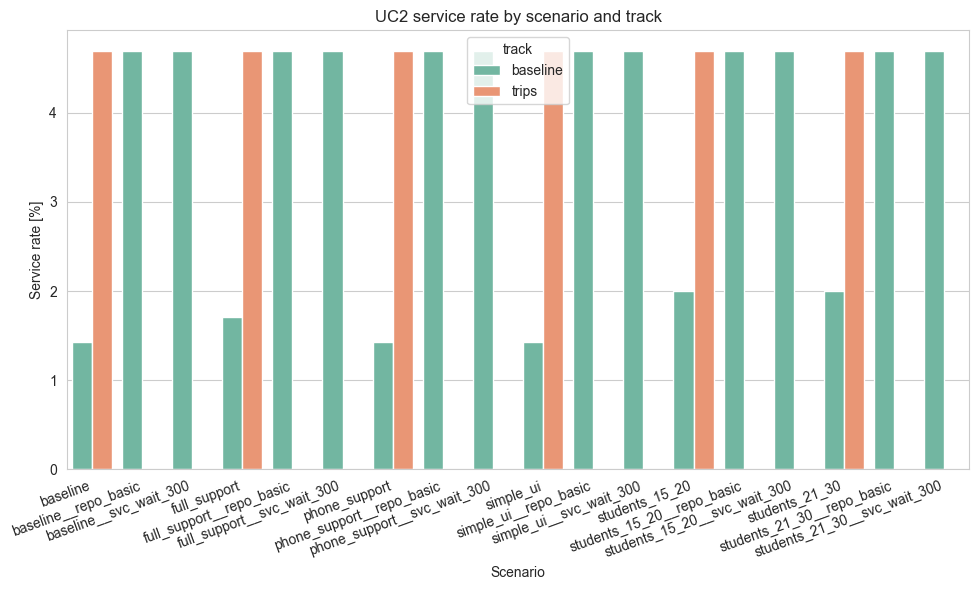

In [8]:
uc2_results_dir = REPO_ROOT / "studies" / "uc2_age_based" / "results"
uc2_df = load_case_results(uc2_results_dir)

if uc2_df.empty:
    print("No UC2 results found in:", uc2_results_dir)
else:
    uc2_df = add_track_cols(uc2_df)
    uc2_df["avg_wait_min"] = uc2_df["avg_wait_s"] / 60
    uc2_df["median_wait_min"] = uc2_df["median_wait_s"] / 60
    uc2_df["p90_wait_min"] = uc2_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
        "num_travelers",
        "total_vkm",
    ]
    display(uc2_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=uc2_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("UC2 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

### Interpretation UC2 (digitale Kompetenz)

Konfiguration:
- Variiert werden: Entscheidungszeit, Wartezeit-Toleranz, Gehgeschwindigkeit, Boarding-Zeit.
- Die Flotte bleibt konstant, nur das Nutzerverhalten aendert sich.

Warum sehen die Unterschiede klein aus?
- Bei geringer Nachfrage sind die Kennzahlen oft stabil und differenzieren nur leicht.
- Die Aenderungen wirken eher auf Akzeptanz/Abbruch als auf die reine Kapazitaet.

## UC3 results (baseline vs trips)

Scenarios include baseline, mixed_20, mixed_30, mixed_50. Trips results are suffixed with `__trips`.

,scenario_base,track,service_rate_pct,avg_wait_min,median_wait_min,p90_wait_min,utilization_pct,num_users,num_travelers,total_vkm
0,baseline,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0,5.0,17.604296
1,baseline,trips,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
2,baseline__repo_basic,baseline,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
3,baseline__svc_wait_300,baseline,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
4,mixed_20,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0,5.0,17.604296
5,mixed_20,trips,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
6,mixed_20__repo_basic,baseline,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
7,mixed_20__svc_wait_300,baseline,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778
8,mixed_30,baseline,1.428571,1.9,2.0,2.3,2.437500,5.0,5.0,17.604296
9,mixed_30,trips,4.687500,3.0,3.0,3.8,1.815962,3.0,3.0,8.350778


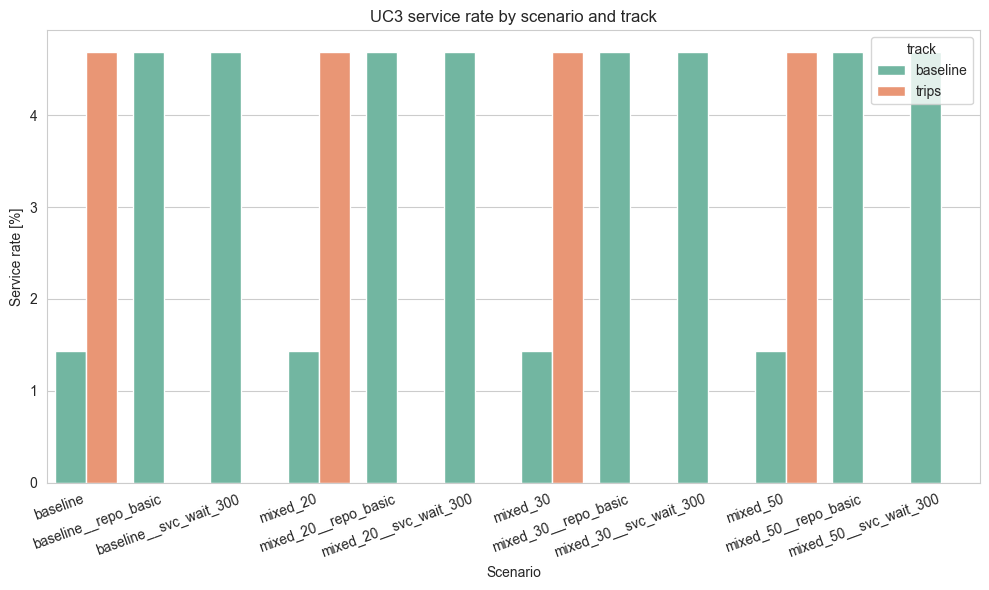

In [9]:
uc3_results_dir = REPO_ROOT / "studies" / "uc3_accessibility" / "results"
uc3_df = load_case_results(uc3_results_dir)

if uc3_df.empty:
    print("No UC3 results found in:", uc3_results_dir)
else:
    uc3_df = add_track_cols(uc3_df)
    uc3_df["avg_wait_min"] = uc3_df["avg_wait_s"] / 60
    uc3_df["median_wait_min"] = uc3_df["median_wait_s"] / 60
    uc3_df["p90_wait_min"] = uc3_df["p90_wait_s"] / 60
    display_cols = [
        "scenario_base",
        "track",
        "service_rate_pct",
        "avg_wait_min",
        "median_wait_min",
        "p90_wait_min",
        "utilization_pct",
        "num_users",
        "num_travelers",
        "total_vkm",
    ]
    display(uc3_df.sort_values(["scenario_base", "track"])[display_cols])

    ax = sns.barplot(
        data=uc3_df,
        x="scenario_base",
        y="service_rate_pct",
        hue="track",
        palette="Set2",
    )
    ax.set_title("UC3 service rate by scenario and track")
    ax.set_xlabel("Scenario")
    ax.set_ylabel("Service rate [%]")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

### Interpretation UC3 (Barrierefreiheit)

Konfiguration:
- Flottenmix: baseline (nur Standard), mixed_20/30/50 mit steigenden Anteilen barrierefreier Fahrzeuge.
- Wartezeitvorgaben sind identisch; variiert wird nur die Zusammensetzung.

Warum sind die Unterschiede gering?
- Wenn die Nachfrage nach barrierefreien Fahrten niedrig ist, aendert der Mix die Kennzahlen kaum.
- Bei insgesamt geringer Nachfrage dominiert das Grundrauschen der Kennzahlen.